In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/ml_base.csv", parse_dates=["date"])
df = df.sort_values(["pays", "date"])

last = df.groupby("pays").agg(
    population=("population", "first"),
    cases=("cas_cumules", "last"),
    deaths=("deces_cumules", "last"),
)

weekly = df.dropna(subset=["cas_hebdomadaires"])
peak_idx = weekly.groupby("pays")["cas_hebdomadaires"].idxmax()
peak = weekly.loc[peak_idx, ["pays", "date", "cas_hebdomadaires"]].set_index("pays")
peak.columns = ["peak_date", "peak_week_cases"]

feat = last.join(peak)
feat["cases_100k"] = feat["cases"] / feat["population"] * 1e5
feat["deaths_100k"] = feat["deaths"] / feat["population"] * 1e5
feat["cfr"] = feat["deaths"] / feat["cases"]
feat["peak_week_100k"] = feat["peak_week_cases"] / feat["population"] * 1e5
feat["peak_day"] = (feat["peak_date"] - df["date"].min()).dt.days

cols = ["cases_100k", "deaths_100k", "cfr", "peak_week_100k", "peak_day"]
feat = feat[feat["population"] >= 1_000_000]
feat = feat.replace([np.inf, -np.inf], np.nan).dropna(subset=cols)
print(feat.shape)
feat[cols].describe().round(2)

(159, 10)


,cases_100k,deaths_100k,cfr,peak_week_100k,peak_day
count,159.00,159.00,159.00,159.00,159.00
mean,15185.42,126.24,0.05,1074.16,679.55
std,17909.59,141.22,0.47,1466.78,152.16
min,0.00,0.02,0.00,0.00,109.00
25%,566.55,10.84,0.01,43.87,639.50
50%,7108.26,74.14,0.01,369.06,729.00
75%,23825.33,202.76,0.02,1691.96,746.00
max,66478.28,662.14,6.00,7976.54,1050.00


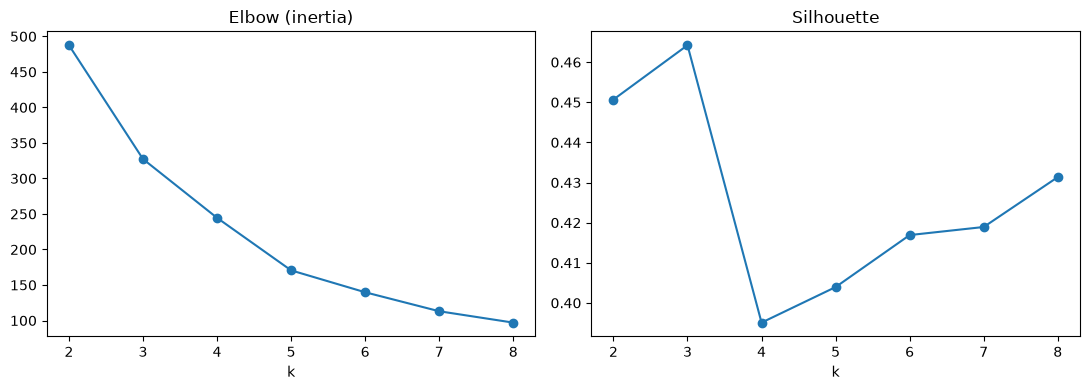

[0.451, 0.464, 0.395, 0.404, 0.417, 0.419, 0.431]


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

X = StandardScaler().fit_transform(feat[cols])

ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print([round(s, 3) for s in sils])

In [3]:
print(feat.sort_values("cfr", ascending=False)[["population", "cases", "deaths", "cfr"]].head(5))
print(feat.sort_values("cases_100k")[["population", "cases", "deaths", "cases_100k"]].head(5))

             population    cases  deaths       cfr
pays                                              
North Korea    26232530      1.0     6.0  6.000000
Yemen          37140234  11945.0  2159.0  0.180745
Sudan          48066930  63829.0  5017.0  0.078601
Syria          21628837  57467.0  3164.0  0.055058
Somalia        17271435  27324.0  1361.0  0.049810
             population    cases  deaths  cases_100k
pays                                                
North Korea    26232530      1.0     6.0    0.003812
Yemen          37140234  11945.0  2159.0   32.161887
Niger          24502145   9508.0   315.0   38.804766
Chad           17828274   7679.0   194.0   43.072033
Tanzania       62830410  42906.0   846.0   68.288588


In [4]:
feat2 = feat[(feat["cfr"] <= 1) & (feat["cases_100k"] > 1)].copy()
print(len(feat2))

X = StandardScaler().fit_transform(feat2[cols])
K = 3                      # revisit after rerunning the elbow/silhouette cell on feat2
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
feat2["cluster"] = km.labels_
feat2.groupby("cluster")[cols].mean().round(2).join(feat2["cluster"].value_counts().rename("n"))

158


,cases_100k,deaths_100k,cfr,peak_week_100k,peak_day,n
cluster,,,,,,
0,1619.73,22.09,0.02,103.98,585.88,73
1,45452.58,212.13,0.00,3498.44,756.24,33
2,15313.59,220.38,0.02,918.32,759.13,52
